<a href="https://colab.research.google.com/github/xl4357/MSSP6070/blob/main/WeeklyModules/Week12/Week12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv(
    "/content/Student Performance Data (1).csv"
)

display(df.head())

print("Shape:", df.shape)
print("Missing values:")
print(df.isna().sum())

assert (
    df["total score"]
    == df[["math score", "reading score", "writing score"]].sum(axis=1)
).all()

,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


Shape: (1000, 10)
Missing values:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
math score                     0
reading score                  0
writing score                  0
total score                    0
test preparation course        0
admission prospect             0
dtype: int64


In [6]:
males = df[df["gender"] == "male"]
prepared = males.loc[males["test preparation course"] == "completed", "total score"]
not_prepared = males.loc[males["test preparation course"] == "none", "total score"]

t_stat, p_value = stats.ttest_ind(prepared, not_prepared, equal_var=False)
print(f"Prepared: n={len(prepared)}, mean={prepared.mean():.2f}")
print(f"Not prepared: n={len(not_prepared)}, mean={not_prepared.mean():.2f}")
print(f"Difference: {prepared.mean() - not_prepared.mean():.2f}")
print(f"t={t_stat:.3f}, p={p_value:.3g}")
print("Significant at alpha=0.05:", p_value < 0.05)


Prepared: n=174, mean=212.34
Not prepared: n=308, mean=189.13
Difference: 23.21
t=6.181, p=1.73e-09
Significant at alpha=0.05: True


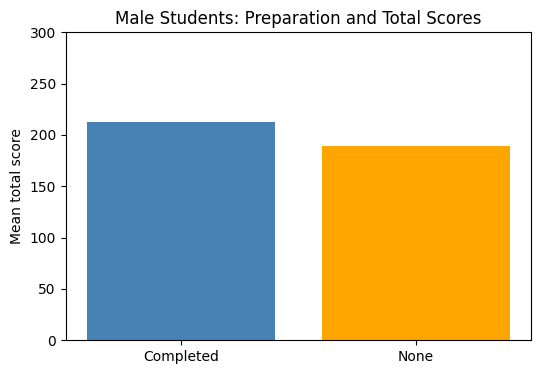

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Completed", "None"], [prepared.mean(), not_prepared.mean()], color=["steelblue", "orange"])
ax.set(title="Male Students: Preparation and Total Scores", ylabel="Mean total score", ylim=(0, 300))
plt.show()


In [9]:
prepared_male_mask = (df["gender"] == "male") & (df["test preparation course"] == "completed")
a = df.loc[prepared_male_mask, "total score"]
b = df.loc[~prepared_male_mask, "total score"]
result = stats.ttest_ind(a, b, equal_var=False)
print(f"Prepared males: n={len(a)}, mean={a.mean():.2f}")
print(f"All other students: n={len(b)}, mean={b.mean():.2f}")
print(f"Difference={a.mean() - b.mean():.2f}, t={result.statistic:.3f}, p={result.pvalue:.3g}")


Prepared males: n=174, mean=212.34
All other students: n=826, mean=201.41
Difference=10.94, t=3.257, p=0.00127


In [10]:
def welch_comparison(data, group_col, group_a, group_b, score_col):
    a = data.loc[data[group_col] == group_a, score_col].dropna()
    b = data.loc[data[group_col] == group_b, score_col].dropna()
    result = stats.ttest_ind(a, b, equal_var=False)
    return {
        "comparison": f"{group_a} vs {group_b}",
        "score": score_col,
        "n_a": len(a), "n_b": len(b),
        "mean_a": round(a.mean(), 2), "mean_b": round(b.mean(), 2),
        "difference": round(a.mean() - b.mean(), 2),
        "t": round(float(result.statistic), 3),
        "p": float(result.pvalue)
    }

results = [
    welch_comparison(df, "lunch", "standard", "free/reduced", "total score"),
    welch_comparison(df, "gender", "female", "male", "math score"),
    welch_comparison(df, "gender", "female", "male", "reading score"),
    welch_comparison(df, "gender", "female", "male", "writing score")
]
summary = pd.DataFrame(results)
summary["significant_0.05"] = summary["p"] < 0.05
display(summary)


,comparison,score,n_a,n_b,mean_a,mean_b,difference,t,p,significant_0.05
0,standard vs free/reduced,total score,645,355,212.51,186.60,25.91,9.323,1.582969e-19,True
1,female vs male,math score,518,482,63.63,68.73,-5.10,-5.398,8.420838e-08,True
2,female vs male,reading score,518,482,72.61,65.47,7.14,7.968,4.376297e-15,True
3,female vs male,writing score,518,482,72.47,63.31,9.16,9.998,1.711809e-22,True


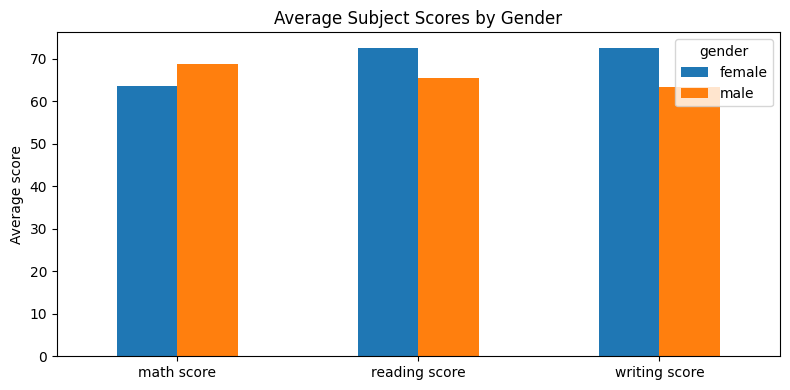

In [11]:
gender_scores = df.groupby("gender")[["math score", "reading score", "writing score"]].mean().T
gender_scores.plot(kind="bar", figsize=(8, 4))
plt.ylabel("Average score")
plt.title("Average Subject Scores by Gender")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
